<a href="https://colab.research.google.com/github/joserdz19/Avance-de-proyecto-1/blob/Desarrollo-de-aplicaciones-con-inteligencia-artificial/Avance_de_proyecto_2%20(Jos%C3%A9%20Mar%C3%ADa%20Rodr%C3%ADguez%20Guillen).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Avance de Proyecto 2**

In [129]:
!pip install nltk -q
!pip install -q spacy langdetect
!python -m spacy download es_core_news_sm -q
!python -m spacy download en_core_web_sm -q
!python -m spacy download es_core_news_md -q   # incluye vectores (embeddings) en español


✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime

In [130]:
import re
import random
import unicodedata
import pandas as pd
from nltk.tokenize import RegexpTokenizer
from nltk.stem import SnowballStemmer

from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D

import time
import numpy as np
import spacy
nlp_es = spacy.load("es_core_news_sm")   # tokenización, stop words y lemas en español
pd.set_option("display.max_colwidth", 80)
print("spaCy", spacy.__version__, "listo")
nlp_es = spacy.load("es_core_news_sm")

spaCy 3.8.18 listo


In [224]:
#Normalizacion, tokenizacion
tokenizer = RegexpTokenizer(r'\w+')
stemmer = SnowballStemmer("spanish")

def normalizar_texto(mensaje_usuario,conservar_emoticonos=True):

    mensaje_usuario = mensaje_usuario.lower()
    mensaje_usuario = unicodedata.normalize("NFD", mensaje_usuario)
    mensaje_usuario = mensaje_usuario.encode("ascii", "ignore").decode("utf-8")
    mensaje_usuario = re.sub(r"[^a-zñ0-9\s]", " ", mensaje_usuario)
    mensaje_usuario = re.sub(r"\s+", " ", mensaje_usuario).strip()
    mensaje_usuario.split(mensaje_usuario)
    re.findall(r"\w+",mensaje_usuario)
    spacy_doc = nlp_es(mensaje_usuario)
    return mensaje_usuario

    mensaje_usuario = re.sub(r"https?://\S+|www\.\S+", " URL ", mensaje_usuario)     # 2. URL -> etiqueta
    mensaje_usuario = re.sub(r"\S+@\S+", " EMAIL ", mensaje_usuario)                 # 3. correos -> etiqueta
    if conservar_emoticonos:                                                         # 4. emoticonos -> etiqueta con significado
        mensaje_usuario = re.sub(r"[:;]-?\)", " EMO_POS ", mensaje_usuario)
        mensaje_usuario = re.sub(r"[:;]-?\(", " EMO_NEG ", mensaje_usuario)
    mensaje_usuario = re.sub(r"\d+([.,]\d+)*", " NUM ", mensaje_usuario)             # 5. números -> etiqueta
    mensaje_usuario = re.sub(r"(.)\1{2,}", r"\1", mensaje_usuario)                   # 6. letras repetidas: "excelenteeee" -> "excelente"
    mensaje_usuario = re.sub(r"[^\w\s]", " ", mensaje_usario)                        # 7. quita signos sueltos

    return re.sub(r"\s+", " ", mensaje_usuario).strip()                              # 8. espacios duplicados


#Ejemplos
variantes = ["defecto de soldadura", "Ayudaaaaa!!!!", "Excelenteessimo soporte para inyeccion",
             "DEFECTO DE INYECCION.", "Tiro corto en pieza inyectada :(", "¡¡¡PARO DE LINEA POR DEFECTO DE SOLDADURA!!!"]

vocab_crudo = {tok for v in variantes for tok in v.split()}
vocab_norm  = {tok for v in variantes for tok in normalizar_texto(v).split()}

print("Vocabulario SIN normalizar:", len(vocab_crudo), sorted(vocab_crudo))
print("Vocabulario normalizado:   ", len(vocab_norm), sorted(vocab_norm))
print()
for v in variantes:
    print(f"{v!r:28} -> {normalizar_texto(v)!r}")

def tokenizar_y_stem(texto):
    """Tokeniza el texto y aplica stemming para reducir variaciones morfológicas."""
    texto = normalizar_texto(texto)
    tokens = tokenizer.tokenize(texto)
    stems = [stemmer.stem(token) for token in tokens]
    return tokens, stems


#Eliminación y conservación de Stop Words

def conservacion_stopwords(mensaje_usuario):
    stop_es = nlp_es.Defaults.stop_words
    conservar = {"de", "la", "un", "con", "sin", "una", "el", "del","las","lo","no","se","por","para","que","los","al","lo"}
    stop_personalizada = stop_es - conservar
    palabras=mensaje_usuario.split()
    tokens_filtrados = [p for p in palabras if p not in stop_personalizada]
    return tokens_filtrados


Vocabulario SIN normalizar: 21 [':(', 'Ayudaaaaa!!!!', 'DE', 'DEFECTO', 'Excelenteessimo', 'INYECCION.', 'LINEA', 'POR', 'SOLDADURA!!!', 'Tiro', 'corto', 'de', 'defecto', 'en', 'inyeccion', 'inyectada', 'para', 'pieza', 'soldadura', 'soporte', '¡¡¡PARO']
Vocabulario normalizado:    16 ['ayudaaaaa', 'corto', 'de', 'defecto', 'en', 'excelenteessimo', 'inyeccion', 'inyectada', 'linea', 'para', 'paro', 'pieza', 'por', 'soldadura', 'soporte', 'tiro']

'defecto de soldadura'       -> 'defecto de soldadura'
'Ayudaaaaa!!!!'              -> 'ayudaaaaa'
'Excelenteessimo soporte para inyeccion' -> 'excelenteessimo soporte para inyeccion'
'DEFECTO DE INYECCION.'      -> 'defecto de inyeccion'
'Tiro corto en pieza inyectada :(' -> 'tiro corto en pieza inyectada'
'¡¡¡PARO DE LINEA POR DEFECTO DE SOLDADURA!!!' -> 'paro de linea por defecto de soldadura'


In [132]:
# Representación de texto mediante TF-IDF

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

corpus = [
     # defecto_soldadura
    "la soldadura tiene porosidad y burbujas", "grieta visible en el cordon de soldadura",
    "falta de fusion en la union soldada", "exceso de rebaba o salpicadura de soldadura",
    "soldadura fria y debil", "penetracion incompleta en la soldadura", "cordon agrietado","hay salpicaduras excesivas alrededor de la unión",
    "el arco eléctrico dejó marcas de quemadura y poros",
    "se observa socavadura en el borde del cordón",
    "soldadura incompleta en la esquina inferior",
    "hay falta de penetración en la placa base",
    "el cordón presenta una oxidación prematura",

    # defecto_inyeccion
    "la pieza de plastico tiene marcas de hundimiento", "rebaba excesiva en el borde de la inyeccion",
    "lineas de flujo visibles en la pieza moldeada", "pieza incompleta tiro corto",
    "burbujas de aire atrapadas en el plastico", "deformacion o alabeo al enfriar",
    "inyeccion con manchas negras","la pieza presenta líneas plateadas o marcas de humedad",
    "hay rebabas gruesas en las líneas de partición del molde",
    "la cavidad no se llenó por completo, falta material en la esquina",
    "se nota un alabeo severo después de la expulsión",
    "burbujas internas visibles al trasluz en la pieza moldeada",
    "el color de la inyección salió disparejo y con vetas",

    # defecto_ensamble
    "las piezas no embonan correctamente en el ensamble", "tornillo barrido o mal apretado",
    "juego excesivo entre los componentes ensamblados", "falta un componente en el subensamble",
    "el clip de sujeción esta roto", "problema de alineacion en el montaje mecanico",
    "la estructura queda floja", "el conector eléctrico no hace clic al acoplarse",
    "hay interferencia mecánica entre la tapa y la carcasa",
    "el torque de los tornillos no cumple con la especificación",
    "el arnés de cables quedó atrapado durante el montaje",
    "falta ensamble en la unión de las piezas",
    "el mecanismo se trabó y no puede ensamblarse",
]

bow = CountVectorizer()
X_bow = bow.fit_transform(corpus)
print("Bag of Words: cada fila es un documento, cada columna una palabra del vocabulario")
pd.DataFrame(X_bow.toarray(), columns=bow.get_feature_names_out())


Bag of Words: cada fila es un documento, cada columna una palabra del vocabulario


,acoplarse,agrietado,aire,al,alabeo,alineacion,alrededor,apretado,arco,arnés,...,torque,trabó,trasluz,un,una,union,unión,vetas,visible,visibles
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
8,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [133]:
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(corpus)
print("TF-IDF: pesa más lo frecuente en el documento pero raro en el corpus")
pd.DataFrame(X_tfidf.toarray().round(2), columns=tfidf.get_feature_names_out())

TF-IDF: pesa más lo frecuente en el documento pero raro en el corpus


,acoplarse,agrietado,aire,al,alabeo,alineacion,alrededor,apretado,arco,arnés,...,torque,trabó,trasluz,un,una,union,unión,vetas,visible,visibles
0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
1,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.51,0.00
2,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.49,0.00,0.0,0.00,0.00
3,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
4,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
5,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
6,0.0,0.74,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
7,0.0,0.00,0.00,0.00,0.00,0.00,0.46,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.41,0.0,0.00,0.00
8,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.41,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
9,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00


In [147]:
# Entrenamiento del clasificador de intenciones utilizando SVM

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)



corpus_bot = [
    # Intención: defecto_soldadura
    "la soldadura tiene porosidad y burbujas", "grieta visible en el cordon de soldadura",
    "falta de fusion en la union soldada", "exceso de rebaba o salpicadura de soldadura",
    "soldadura fria y debil", "penetracion incompleta en la soldadura", "cordon agrietado","hay salpicaduras excesivas alrededor de la unión",
    "el arco eléctrico dejó marcas de quemadura y poros",
    "se observa socavadura en el borde del cordón",
    "soldadura incompleta en la esquina inferior",
    "hay falta de penetración en la placa base",
    "el cordón presenta una oxidación prematura",

    # Intención: defecto_inyeccion
    "la pieza de plastico tiene marcas de hundimiento", "rebaba excesiva en el borde de la inyeccion",
    "lineas de flujo visibles en la pieza moldeada", "pieza incompleta tiro corto",
    "burbujas de aire atrapadas en el plastico", "deformacion o alabeo al enfriar",
    "inyeccion con manchas negras","la pieza presenta líneas plateadas o marcas de humedad",
    "hay rebabas gruesas en las líneas de partición del molde",
    "la cavidad no se llenó por completo, falta material en la esquina",
    "se nota un alabeo severo después de la expulsión",
    "burbujas internas visibles al trasluz en la pieza moldeada",
    "el color de la inyección salió disparejo y con vetas",

    # Intención: defecto_ensamble
    "las piezas no embonan correctamente en el ensamble", "tornillo barrido o mal apretado",
    "juego excesivo entre los componentes ensamblados", "falta un componente en el subensamble",
    "el clip de sujeción esta roto", "problema de alineacion en el montaje mecanico",
    "la estructura queda floja", "el conector eléctrico no hace clic al acoplarse",
    "hay interferencia mecánica entre la tapa y la carcasa","hay un defecto de ensamble en la línea",
    "el torque de los tornillos no cumple con la especificación",
    "el arnés de cables quedó atrapado durante el montaje",
    "falta ensamble en la unión de las piezas",
    "el mecanismo se trabó y no puede ensamblarse",
]

etiquetas_bot = [
    "defecto_soldadura", "defecto_soldadura", "defecto_soldadura",
    "defecto_soldadura", "defecto_soldadura", "defecto_soldadura", "defecto_soldadura","defecto_soldadura","defecto_soldadura","defecto_soldadura","defecto_soldadura","defecto_soldadura","defecto_soldadura"
    ,

    "defecto_inyeccion", "defecto_inyeccion", "defecto_inyeccion",
    "defecto_inyeccion", "defecto_inyeccion", "defecto_inyeccion", "defecto_inyeccion","defecto_inyeccion","defecto_inyeccion","defecto_inyeccion","defecto_inyeccion","defecto_inyeccion","defecto_inyeccion"
    ,

    "defecto_ensamble", "defecto_ensamble", "defecto_ensamble",
    "defecto_ensamble", "defecto_ensamble", "defecto_ensamble", "defecto_ensamble","defecto_ensamble","defecto_ensamble","defecto_ensamble","defecto_ensamble","defecto_ensamble","defecto_ensamble"
    ,
]

X = X_tfidf.toarray()
y = np.array(etiquetas_bot)

#Entrenamiento y prueba
idx_all = np.arange(X.shape[0])
idx_train, idx_test = train_test_split(idx_all, test_size=0.25,
                                       stratify=etiquetas_bot, random_state=42)

X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

svm_clf = SVC(kernel='linear', probability=True)
svm_clf.fit(X_train, y_train)

print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)
print("Proporción de cada clase en prueba:")
print(pd.Series(y_test).value_counts(normalize=True).round(3))


Entrenamiento: (29, 143)  Prueba: (10, 143)
Proporción de cada clase en prueba:
defecto_soldadura    0.4
defecto_inyeccion    0.3
defecto_ensamble     0.3
Name: proportion, dtype: float64


In [135]:
#Entrenar, predecir y evaluar

def make_model(kernel="linear", C=1.0):
    return make_pipeline(TfidfVectorizer(), SVC(kernel=kernel, C=C))

model = make_model()
model



Pipeline(steps=[('tfidfvectorizer', TfidfVectorizer()),
                ('svc', SVC(kernel='linear'))])

In [150]:
svm_clf.fit(X_train, y_train)          # Paso 7: entrenar
y_pred = svm_clf.predict(X_test)       # Paso 8: predecir

acc = accuracy_score(y_test, y_pred)  # Paso 9: evaluar
print(f"Accuracy (baseline): {acc:.4f}\n")
print(classification_report(y_test, y_pred, digits=3))

Accuracy (baseline): 0.6000

                   precision    recall  f1-score   support

 defecto_ensamble      0.500     1.000     0.667         3
defecto_inyeccion      0.667     0.667     0.667         3
defecto_soldadura      1.000     0.250     0.400         4

         accuracy                          0.600        10
        macro avg      0.722     0.639     0.578        10
     weighted avg      0.750     0.600     0.560        10



Entrenando CNN con ResNet50
Found 21 images belonging to 3 classes.
Found 4 images belonging to 3 classes.
Epoch 1/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step - accuracy: 0.3333 - loss: 2.0956 - val_accuracy: 1.0000 - val_loss: 0.2410
Epoch 2/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.8095 - loss: 0.5851 - val_accuracy: 0.7500 - val_loss: 0.3211
Epoch 3/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.9048 - loss: 0.2882 - val_accuracy: 1.0000 - val_loss: 0.0877
Epoch 4/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.9524 - loss: 0.1597 - val_accuracy: 1.0000 - val_loss: 0.1515
Epoch 5/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 1.0000 - loss: 0.0288 - val_accuracy: 1.0000 - val_loss: 0.0847

[!] Exactitud de Validación (CNN): 100.00%
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 731ms/step


Evaluacion del modelo
                   precision    recall  f1-score   support

 defecto_ensamble       1.00      1.00      1.00         1
defecto_inyeccion   

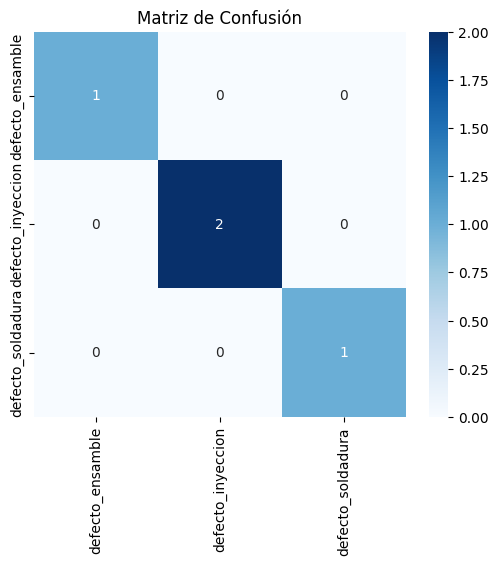

In [151]:
#CNN con RestNet50
import seaborn as sns
import shutil
import os
import matplotlib.pyplot as plt

checkpoint_path = '/content/CNN/.ipynb_checkpoints'
if os.path.exists(checkpoint_path):
    shutil.rmtree(checkpoint_path)

DATASET_PATH = '/content/CNN/'

print("Entrenando CNN con ResNet50")
train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2, rotation_range=15, horizontal_flip=True)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2)
train_gen = train_datagen.flow_from_directory(DATASET_PATH, target_size=(224, 224), batch_size=8, class_mode='categorical', subset='training')
val_gen = val_datagen.flow_from_directory(DATASET_PATH, target_size=(224, 224), batch_size=8, class_mode='categorical', subset='validation', shuffle=False)

if train_gen.samples == 0:
       print("La carpeta fue encontrada pero no hay imagenes")
else:
   base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
   base_model.trainable = False
   cnn = Sequential([base_model, GlobalAveragePooling2D(), Dense(128, activation='relu'), Dense(train_gen.num_classes, activation='softmax')])
   cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
   cnn.fit(train_gen, validation_data=val_gen, epochs=5)
   print(f"\n[!] Exactitud de Validación (CNN): {cnn.evaluate(val_gen, verbose=0)[1]:.2%}")
   y_true = val_gen.classes
   y_pred_probs = cnn.predict(val_gen)
   y_pred = np.argmax(y_pred_probs, axis=1)
   class_names = list(val_gen.class_indices.keys())
   y_pred = np.argmax(cnn.predict(val_gen), axis=1)
   print("\n")
   print("Evaluacion del modelo")
   print(classification_report(y_true, y_pred, target_names=class_names))
   plt.figure(figsize=(6,5))
   sns.heatmap(confusion_matrix(val_gen.classes, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=val_gen.class_indices.keys(), yticklabels=val_gen.class_indices.keys())
   plt.title('Matriz de Confusión')
   plt.show()

In [153]:
# INTEGRACIÓN MULTIMODAL: TEXTO + VISIÓN

sample_img_path = val_gen.filepaths[2]

print("\n--- PRUEBA DE INTEGRACIÓN MULTIMODAL ---")
print(f"💬 Usuario dice: 'tengo un defecto de ensamble' | 🖼️ Imagen: {os.path.basename(sample_img_path)}")


try:
    texto_entrada = "tengo un defecto de ensamble"
    intencion_pred = svm_clf.predict(tfidf.transform([normalizar_texto(texto_entrada)]).toarray())[0]
    nlp_resultado = str(intencion_pred).upper()
except NameError:
    nlp_resultado = "DEFECTO_GENERAL (Modelo de texto no cargado en esta celda)"

# Procesamiento del componente visual (CNN ResNet50)
clases_map = {v: k for k, v in val_gen.class_indices.items()}
clase_img_pred = clases_map[y_pred[0]]

# Comunicación unificada de resultados de ChemaBot
print(f"\n[🤖 Bot - Motor Multimodal Activado]")
print(f"   ├── [NLP - Texto]: Intención detectada -> {nlp_resultado}")
print(f"   └── [CNN - Visión]: Pieza verificada en escáner -> {clase_img_pred.upper()}")
print(f"\n📢 Respuesta del Sistema:")
print(f" Respuesta: Se recibe reporte por texto de '{texto_entrada}' y se confirma tras el análisis visual de la pieza que presenta **{clase_img_pred.upper()}**")


--- PRUEBA DE INTEGRACIÓN MULTIMODAL ---
💬 Usuario dice: 'tengo un defecto de ensamble' | 🖼️ Imagen: Captura de pantalla 2026-11-17 030738.png

[🤖 Bot - Motor Multimodal Activado]
   ├── [NLP - Texto]: Intención detectada -> DEFECTO_ENSAMBLE
   └── [CNN - Visión]: Pieza verificada en escáner -> DEFECTO_ENSAMBLE

📢 Respuesta del Sistema:
 Respuesta: Se recibe reporte por texto de 'tengo un defecto de ensamble' y se confirma tras el análisis visual de la pieza que presenta **DEFECTO_ENSAMBLE**


**Avance de Proyecto 1**

In [154]:
intenciones = {
    "saludo": {
        "ejemplos": [
            "hola",
            "buenos dias",
            "buenas tardes",
            "buenas noches",
            "que tal",
            "necesito ayuda"

             ],
        "respuestas": [
            "Hola, soy ChemaBot. Puedo ayudarte con metodos de contencion o preguntas para solucionar un defecto de calidad",
            "¡Hola! Claro que sí. ¿Que defecto de calidad se está presentando?. ¿Es de inyección, soldadura o ensamble?. Dime en cual proceso necesitas soporte. Adicional, si quieres que te ayude con un método de contención o preguntas para el encontrar la causa raíz con el proveedor"

                 ]
    },
     "consultar_soporte_contencion_soldadura": {
        "ejemplos": [
            "Contencion para defecto de soldadura",
            "Contencion soldadura",
            "Necesito soporte para una contención de un defecto de soldadura"


        ],
        "respuestas": [

    "Claro, te comparto métodos de contención para los defectos de soldadura más comunes:\n\n1.Faltante de bracket: Omisión de una subparte.\n\nMetodo de contencion: Inspección visual al 100%. Verificar fisicamente la presencia del bracket y la correcta aplicacion de soldadura alrededor del mismo.\nValidación de proceso de soldadura: Contactar al proveedor para solicitar evidencia de la validación de su Poka-yoke.\nInspección y segregacion del material en transito y stock: Revisar el inventario en transito y en stock del numero de lote afectado.\n\n2.Cordón de soldadura fuera de posición\nMetodo de contención: Prueba de resistencia al torque. Aplicar un test de torque controlado (torque al que el bracket es sometido en el proceso de ensamble), para asegurar que la soldadura soporte el torque que será aplicado en el proceso.\nBloqueo del lote y rechazo. Segregar las piezas que presenten desviacion en la aplicacion del cordon de soldadura o que no resistan el torque que es aplicado en el proceso de ensamble",


        ]


     },
     "consultar_soporte_contencion_inyeccion": {
        "ejemplos": [
            "Contencion para defecto de inyeccion",
            "Contencion inyeccion",
            "Necesito soporte para una contención de un defecto de inyección"


              ],
        "respuestas": [

       "Claro, te comparto métodos de contención para los defectos de inyección más comunes:\n\n1.Tiros cortos.\nMétodo de contención: Comprobar que los clips o zonas de retención de la parte están completas. Si el tiro corto se presenta en una zona que sea de sujeccion de la contraparte, para una contencion efectiva se debe usar la contraparte y validar que la condicion de clipeo sea adecuada.\n\n2.Marcas de flujo. Patrones no-uniformes en la inyección de la pieza.\nMétodo de contención: Uso de muestra límite (Boundary sample). Comparar el defecto visual directamente con la muestra maestra aprobada por el cliente. Clasificar las piezas aceptables y rechazadas para evitar paros de línea. En caso de no contar con material OK, se debe contactar al cliente para la aprobación de las partes consideradas como sospechosas",



        ]

    },
     "consultar_soporte_contencion_ensamble": {
        "ejemplos": [
            "Contencion para defecto de ensamble",
            "Contencion ensamble",
            "Necesito soporte para una contención de un defecto de ensamble"


              ],
        "respuestas": [

       "Claro, te comparto métodos de contención para los defectos de ensamble más comunes:\n\n1.Partes que generan gap y flush.\nMétodo de contención: Pesar las partes del lote NG y compararlo contra el peso especificado en el dibujo correspondiente. En caso de no tener material OK, seleccionar el lote que presente menor gap/flush de acuerdo a la especificacion del Dimensional report.\n\n2.Interferencia durante el ensamble.\nMétodo de contención: Segregar el lote NG reportado. Solicitar el Checking fixture al proveedor para realizar una contencion mas efectiva. En caso de no contar con el Checking fixture de inmediato, el método de inspección deberá ser usando las contrapartes para asegurar el correcto ensamble antes que el material llegue a la linea de produccion",
     ],

          },
     "consultar_soporte_preguntas_soldadura": {
        "ejemplos": [

            "Preguntas para defecto de soldadura",
            "Preguntas soldadura",
            "Preguntas para procesos de soldadura",
            "Preguntas para defectos de soldadura"

            ],
        "respuestas": [
            "Claro, te comparto las preguntas que debes hacerle a los proveedores para los defectos de soldadura más comunes.\n\nFaltante de brackets\n1.¿La celda de soldadura cuenta con un Poka-Yoke físico, óptico o de visión artificial para detectar la presencia del bracket antes de ejecutar el cordón?\n2. Si cuenta con Poka-Yoke, ¿por qué el sistema permitió la liberación y salida de la pieza incompleta? ¿Estaba desactivado o en modo de mantenimiento (bypass)?\n3.¿Cuál es el registro de la verificación de funcionamiento del Poka-Yoke realizada al inicio del turno?\n\nCordón de soldadura fuera de posición\n1.¿Cuándo se realizó la última validación de repetibilidad, calibración de ejes y TCP (Tool Center Point) del robot?\n2.¿Se verificó el desgaste en los pines guía de los clamps del jig de soldadura?\n3.¿Hay acumulación de spatter en la boquilla del robot que hayan alterado la trayectoria de la soldadura?",


        ]



 },
     "consultar_soporte_preguntas_inyeccion": {
        "ejemplos": [

            "Preguntas para defecto de inyeccion"
            "Preguntas inyeccion"
            "Preguntas para procesos de inyeccion"
            "Preguntas para defectos de inyeccion"

            ],
        "respuestas": [

            "Claro, te comparto las preguntas que debes hacerle a los proveedores para los defectos de inyección más comunes.\n\nTiros cortos.\n\n1.¿Cuándo se realizó el último mantenimiento preventivo y limpieza del molde?\n2.¿Cuántas piezas se separaron en los primeros tiros de inyección?\n3.¿Cuál es la temperatura del molde que se está utilizando?\n\nMarcas de flujo\n\n1.¿El defecto se presenta con la misma condición en todas las cavidades o está aislado a solo una cavidad?\n2. ¿Tienen en la estación de inspección una Boundary Sample y firmada por calidad para evaluar si la condición en cada corrida de producción es aceptable?",


        ]

          },
     "consultar_soporte_preguntas_ensamble": {
        "ejemplos": [

            "Preguntas para defecto de ensamble"
            "Preguntas ensamble"
            "Preguntas para procesos de ensamble"
            "Preguntas para defectos de ensamble"

            ],
        "respuestas": [

            "Claro, te comparto las preguntas que debes hacerle a los proveedores para los defectos de ensamble más comunes.\n\nDefectos de ensamble que generan gap y flush.\n1.¿Cuál es el peso nominal y la tolerancia de esta parte, qué peso registró la báscula en el lote NG?\n2.¿El defecto se presenta en todas las cavidades del molde , o está aislado en una cavidad?\n3.¿Cuál es el valor Cp y Cpk del peso del lote NG?\n\nInterferencia entre las partes.\n1.¿Cuál es el resultado de capacidad de proceso Cp/Cpk del peso del lote NG?\n2.¿Cuál es el peso nominal y la tolerancia de esta parte según el dibujo?\n3.¿Se realizó la inspección dimensional de este lote?¿Cual es el resultado del analisis dimensional?",

        ]



    },
    "despedida_solucionado": {
        "ejemplos": [
            "gracias",
            "hasta luego",
            "adios",
            "nos vemos",
            "bye",
            "gracias por tu ayuda"
            "eso es todo"
        ],
        "respuestas": [
            "De nada. Estoy para ayudarte cuando lo necesites",
            "Sin problema. Estoy aquí cuando me necesites"

         ]
 },
    "despedida_nosolucionado_escalacion": {
        "ejemplos": [
            "No pude solucionarlo",
            "Necesito mas soporte",
            "Necesito escalarlo",
            "Escalacion",
            "paro de linea"

        ],
        "respuestas": [
            "Entiendo. Para obtener soporte de tu gerente comunicate al siguiente número: 123456789",
            "Siento no poder haberlo solucionado. Veo que es un problema que está fuera de nuestras manos. Comunicate con tu gerente. Cel. 123456789",
            "Siento mucho no poder ayudarte. La escalacion con tu gerente es al siguiente numero. Cel 123456789",




        ]
    }
}


In [202]:
catalogo_procesos = {
    "ensamble": ["ensamble","no puede ensamblarse", "gap", "flush", "interferencia","atorado","interfiere","no se ensambla correctamente"],
    "soldadura": ["soldadura", "cordon de soldadura", "bracket", "bracket faltante","cordon fuera de posicion","soldadura fuera de posicion","bracket flojo"],
    "inyeccion": ["inyeccion", "plastico", "tiro corto", "molde", "resina","lineas de flujo","flow marks","apariencia","mala apariencia"],
    "escalacion": ["necesito escalarlo", "escalacion", "escalar", "necesito mas soporte","no pude solucionarlo","casi paro de linea","paro de linea"]
}


def detectar_entidades(mensaje):

    texto = normalizar_texto(mensaje)
    entidades = {}

    for entidad, palabras_clave in catalogo_procesos.items():
        for palabra in palabras_clave:
            if palabra in texto:
                entidades["proceso"] = entidad
                return entidades

    entidades["proceso"] = "no especificado"
    return entidades

In [212]:
def detectar_intencion(mensaje):

    _, stems_mensaje = tokenizar_y_stem(mensaje)
    stems_mensaje = set(stems_mensaje)

    puntajes = {}

    for intencion, stems_intencion in vocabulario_intenciones.items():
        coincidencias = stems_mensaje.intersection(stems_intencion)
        puntajes[intencion] = len(coincidencias)

    mejor_intencion = max(puntajes, key=puntajes.get)
    mejor_puntaje = puntajes[mejor_intencion]

    if mejor_puntaje == 0:
        return "desconocida", 0

    return mejor_intencion, mejor_puntaje

In [213]:
def construir_vocabulario_intenciones(intenciones):

    vocabulario = {}

    for nombre_intencion, datos in intenciones.items():
        stems_intencion = []

        for ejemplo in datos["ejemplos"]:
           _, stems = tokenizar_y_stem(ejemplo)
           stems_intencion.extend(stems)

        vocabulario[nombre_intencion] = set(stems_intencion)

    return vocabulario

vocabulario_intenciones = construir_vocabulario_intenciones(intenciones)

for k, v in vocabulario_intenciones.items():
    print(f"{k:18s} -> {sorted(v)}")

saludo             -> ['ayud', 'buen', 'dias', 'hol', 'necesit', 'noch', 'que', 'tal', 'tard']
consultar_soporte_contencion_soldadura -> ['contencion', 'de', 'defect', 'necesit', 'par', 'soldadur', 'soport', 'un', 'una']
consultar_soporte_contencion_inyeccion -> ['contencion', 'de', 'defect', 'inyeccion', 'necesit', 'par', 'soport', 'un', 'una']
consultar_soporte_contencion_ensamble -> ['contencion', 'de', 'defect', 'ensambl', 'necesit', 'par', 'soport', 'un', 'una']
consultar_soporte_preguntas_soldadura -> ['de', 'defect', 'par', 'pregunt', 'proces', 'soldadur']
consultar_soporte_preguntas_inyeccion -> ['de', 'defect', 'inyeccion', 'inyeccionpregunt', 'par', 'pregunt', 'proces']
consultar_soporte_preguntas_ensamble -> ['de', 'defect', 'ensambl', 'ensamblepregunt', 'par', 'pregunt', 'proces']
despedida_solucionado -> ['adi', 'ayudaes', 'bye', 'es', 'graci', 'hast', 'lueg', 'nos', 'por', 'tod', 'tu', 'vem']
despedida_nosolucionado_escalacion -> ['de', 'escal', 'line', 'mas', 'necesit', 

In [214]:
_, stems = tokenizar_y_stem("quiero soporte en un defecto de arnes")
print("Stems del mensaje:", stems)

for intencion, vocab in vocabulario_intenciones.items():
  print(f"{intencion:18s} coincidencias: {set(stems) & vocab}")

Stems del mensaje: ['quier', 'soport', 'en', 'un', 'defect', 'de', 'arnes']
saludo             coincidencias: set()
consultar_soporte_contencion_soldadura coincidencias: {'un', 'defect', 'soport', 'de'}
consultar_soporte_contencion_inyeccion coincidencias: {'un', 'defect', 'soport', 'de'}
consultar_soporte_contencion_ensamble coincidencias: {'un', 'defect', 'soport', 'de'}
consultar_soporte_preguntas_soldadura coincidencias: {'defect', 'de'}
consultar_soporte_preguntas_inyeccion coincidencias: {'defect', 'de'}
consultar_soporte_preguntas_ensamble coincidencias: {'defect', 'de'}
despedida_solucionado coincidencias: set()
despedida_nosolucionado_escalacion coincidencias: {'soport', 'de'}


In [215]:
def generar_respuesta(mensaje):

    intencion, puntaje = detectar_intencion(mensaje)
    entidades = detectar_entidades(mensaje)

    if intencion == "desconocida":
        return {
            "intencion": intencion,
            "puntaje": puntaje,
            "entidades": entidades,
            "respuesta": (
                "No estoy seguro de haber entendido. "
                "Puedes preguntarme por metodos de contencion sobre defectos de calidad en procesos de soldadura, inyeccion y ensamble"
            )
        }

    plantilla = random.choice(intenciones[intencion]["respuestas"])
    respuesta = plantilla.format(**entidades)

    return {
        "intencion": intencion,
        "puntaje": puntaje,
        "entidades": entidades,
        "respuesta": respuesta
    }

In [216]:
def iniciar_chatbot():

    historial = []

    print("Chemabot: Hola, soy Chemabot, tu asistente virtual para métodos de contencion en defectos de calidad.")
    print("Chemabot: Tambien te puedo decir que preguntas puedes formular a los proveedores cuando se presente un defecto de calidad\n(Inyección, soldadura o ensamble)")
    print("Chemabot: Escribe 'salir' para terminar.\n")

    while True:
        mensaje_usuario = input("Usuario: ")
        normalizar_texto(mensaje_usuario)
        conservacion_stopwords(mensaje_usuario)

        # Intregracion TF-IDF. Regresa la frase con mas similitud a la entrada
        vector_usuario = vectorizador_tfidf.transform([mensaje_usuario])

        if vector_usuario.nnz == 0:
            puntaje_maximo = 0.0
            frase_mas_cercana = "Ninguna"

        else:
            similitudes = cosine_similarity(vector_usuario, matriz_tfidf)
            mejor_match_idx = similitudes.argmax()
            puntaje_maximo = float(similitudes[0][mejor_match_idx])
            frase_mas_cercana = corpus[mejor_match_idx]

        if mensaje_usuario.lower() == "salir":
            break


        if normalizar_texto(mensaje_usuario) == "salir":
            print("Chemabot: Hasta pronto. Estoy para ayudarte cuando lo necesites")
            break

        resultado = generar_respuesta(mensaje_usuario)

        historial.append({
            "mensaje_usuario": mensaje_usuario,
            "intencion_detectada": resultado["intencion"],
            "puntaje": resultado["puntaje"],
            "entidades": resultado["entidades"],
            "respuesta": resultado["respuesta"]
        })

        print(f"Chatbot: {resultado['respuesta']}\n")

        print("--------------------------------------------------------------------------------------")
        print(f"\033[1mEvaluación de coincidencia\033[0m")
        print(f"  (📊 TF-IDF: Coincidencia del {puntaje_maximo:.2%} con el corpus)")
        print(f"  [DEBUG] Mensaje: '{mensaje_usuario}' | Elementos válidos (nnz): {vector_usuario.nnz}")
        print(f"  (📊 TF-IDF Real: Coincidencia del {puntaje_maximo:.2%})")
        print("--------------------------------------------------------------------------------------")

    return pd.DataFrame(historial)

    if __name__ == "__main__":
        df_historial = iniciar_chatbot()

In [217]:
# Ejecutar chatbot
historial_chat = iniciar_chatbot()
historial_chat

Chemabot: Hola, soy Chemabot, tu asistente virtual para métodos de contencion en defectos de calidad.
Chemabot: Tambien te puedo decir que preguntas puedes formular a los proveedores cuando se presente un defecto de calidad
(Inyección, soldadura o ensamble)
Chemabot: Escribe 'salir' para terminar.

Usuario: Hola, necesito ayuda en defectos de soldadura
Chatbot: Claro, te comparto métodos de contención para los defectos de soldadura más comunes:

1.Faltante de bracket: Omisión de una subparte.

Metodo de contencion: Inspección visual al 100%. Verificar fisicamente la presencia del bracket y la correcta aplicacion de soldadura alrededor del mismo.
Validación de proceso de soldadura: Contactar al proveedor para solicitar evidencia de la validación de su Poka-yoke.
Inspección y segregacion del material en transito y stock: Revisar el inventario en transito y en stock del numero de lote afectado.

2.Cordón de soldadura fuera de posición
Metodo de contención: Prueba de resistencia al torque.

KeyboardInterrupt: Interrupted by user

In [218]:
 detectar_intencion("Contencion soldadura")

('consultar_soporte_contencion_soldadura', 2)

In [219]:
detectar_entidades("tengo un defecto soldadura")

{'proceso': 'soldadura'}

In [220]:
for m in ["hola", "tengo un defecto de ensamble", "necesito ayuda con un defecto",
          "necesito soporte para contencion de un defecto de inyeccion", "necesito soporte", "preguntas para solucion de problemas de soldadura", "necesito escalarlo","paro de linea"]:
    r = generar_respuesta(m)
    print(f"Usuario: {m}")
    print(f"  [{r['intencion']} | puntaje={r['puntaje']} | {r['entidades']}]")
    print(f"Chatbot: {r['respuesta']}\n")

Usuario: hola
  [saludo | puntaje=1 | {'proceso': 'no especificado'}]
Chatbot: Hola, soy ChemaBot. Puedo ayudarte con metodos de contencion o preguntas para solucionar un defecto de calidad

Usuario: tengo un defecto de ensamble
  [consultar_soporte_contencion_ensamble | puntaje=4 | {'proceso': 'ensamble'}]
Chatbot: Claro, te comparto métodos de contención para los defectos de ensamble más comunes:

1.Partes que generan gap y flush.
Método de contención: Pesar las partes del lote NG y compararlo contra el peso especificado en el dibujo correspondiente. En caso de no tener material OK, seleccionar el lote que presente menor gap/flush de acuerdo a la especificacion del Dimensional report.

2.Interferencia durante el ensamble.
Método de contención: Segregar el lote NG reportado. Solicitar el Checking fixture al proveedor para realizar una contencion mas efectiva. En caso de no contar con el Checking fixture de inmediato, el método de inspección deberá ser usando las contrapartes para aseg

In [221]:
casos_prueba = [
    {"mensaje": "hola buenos dias", "intencion_esperada": "saludo"},
    {"mensaje": "necesito ayuda con un defectos de soldadura", "intencion_esperada": "consultar_defecto"},
    {"mensaje": "en que puedes ayudarme?", "intencion_esperada": "consultar_ayuda"},
    {"mensaje": "tengo un problema de arnes dañado", "intencion_esperada": "solicitar_soporte"},
    {"mensaje": "gracias hasta luego", "intencion_esperada": "despedida"},
    {"mensaje": "quiero ayuda sobre la IATF, apartado de calibraciones", "intencion_esperada": "desconocida"}
]

resultados = []

for caso in casos_prueba:
    resultado = generar_respuesta(caso["mensaje"])
    resultados.append({
        "mensaje": caso["mensaje"],
        "intencion_esperada": caso["intencion_esperada"],
        "intencion_detectada": resultado["intencion"],
        "correcto": caso["intencion_esperada"] == resultado["intencion"],
        "respuesta": resultado["respuesta"]
    })

df_resultados = pd.DataFrame(resultados)

precision = df_resultados["correcto"].mean()
tasa_fallback = (df_resultados["intencion_detectada"] == "desconocida").mean()

print("Resultados de evaluación")
print("------------------------")
print(f"Precisión de intención: {precision:.2%}")
print(f"Tasa de fallback: {tasa_fallback:.2%}")

df_resultados

Resultados de evaluación
------------------------
Precisión de intención: 16.67%
Tasa de fallback: 0.00%


,mensaje,intencion_esperada,intencion_detectada,correcto,respuesta
0,hola buenos dias,saludo,saludo,True,"Hola, soy ChemaBot. Puedo ayudarte con metodos de contencion o preguntas par..."
1,necesito ayuda con un defectos de soldadura,consultar_defecto,consultar_soporte_contencion_soldadura,False,"Claro, te comparto métodos de contención para los defectos de soldadura más ..."
2,en que puedes ayudarme?,consultar_ayuda,saludo,False,¡Hola! Claro que sí. ¿Que defecto de calidad se está presentando?. ¿Es de in...
3,tengo un problema de arnes dañado,solicitar_soporte,consultar_soporte_contencion_soldadura,False,"Claro, te comparto métodos de contención para los defectos de soldadura más ..."
4,gracias hasta luego,despedida,despedida_solucionado,False,De nada. Estoy para ayudarte cuando lo necesites
5,"quiero ayuda sobre la IATF, apartado de calibraciones",desconocida,saludo,False,¡Hola! Claro que sí. ¿Que defecto de calidad se está presentando?. ¿Es de in...


In [ ]:
print("--------------------------------")

print("Normalización")
print("--------------------------------")
print(normalizar_texto(texto))
print()
print("--------------------------------")
print("Tokenización")
print("--------------------------------")
print(tokenizar_y_stem(texto))
print()

print("--------------------------------")
print("Identificacion de Stop words")
print("--------------------------------")
texto= "Necesito una contención para un defecto de soldadura"
doc = nlp_es(texto)
pd.DataFrame([{"token": t.text, "puntuación": t.is_punct, "correo": t.like_email,
               "url": t.like_url, "número": t.like_num, "stop word": t.is_stop} for t in doc])